In [1]:
# 0. Programming Environment Setup

# Numerical computing and data handling
import numpy as np
import pandas as pd

#modelling`
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.metrics import max_error, mean_absolute_error, mean_absolute_percentage_error, mean_squared_error
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Ridge
from sklearn.kernel_ridge import KernelRidge
from sklearn.linear_model import Lasso
from math import degrees
from sklearn.preprocessing import PolynomialFeatures
from sklearn.ensemble import VotingRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline
from xgboost import XGBRegressor
from sklearn.neighbors import KNeighborsRegressor


#dummy modelling
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    max_error,
    mean_absolute_percentage_error,
    root_mean_squared_error
)


# plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
%matplotlib inline


In [2]:
#1. Data Preparation Part 1

#drop features, use eda_df since we're using a pipeline that will impute missing values
eda_df = pd.read_csv("eda_df.csv")
eda_df = eda_df.drop(columns=['Z', 'N'])
eda_df.head(10)

,element,A,N/Z,Q_beta_keV,Q_alpha_keV,S_n_keV,S_p_keV,log_half_life
0,H,3,2.000000,18.5906,NaN,6257.233,NaN,8.589715
1,HE,6,2.000000,3505.2200,NaN,1710.000,NaN,-0.093288
2,BE,7,0.750000,NaN,-1587.13,10677.000,5606.85,6.662589
3,HE,8,3.000000,10663.8800,NaN,2535.000,NaN,-0.924088
4,LI,8,1.666667,16004.1300,NaN,2032.620,12416.00,-0.075772
5,B,8,0.600000,-12143.0000,NaN,NaN,136.40,-0.113509
6,LI,9,2.000000,13606.4500,NaN,4062.220,13943.75,-0.748849
7,C,9,0.500000,NaN,-10650.00,14225.000,1299.60,-0.897909
8,C,10,0.666667,NaN,-5101.00,21283.500,4006.70,1.285332
9,LI,11,2.666667,20551.1000,NaN,396.000,NaN,-2.057992


In [3]:
# 2. Data Preparation Part 2
#splitting: uses a random split since the data is not skewed 
df_train, df_test = train_test_split(
    eda_df,
    test_size=0.2,  # 20% for testing
    random_state=42  # Ensure reproducibility
)
print(df_train.shape)
df_train.head()

features = [
    "A",
    "N/Z",
    "Q_beta_keV",
    "Q_alpha_keV",
    "S_n_keV",
    "S_p_keV"
]

TARGET = df_train['log_half_life'].name

#Regression metrics function
def get_regression_metrics(model, X, y_true):

    y_predicted = model.predict(X)

    mae = mean_absolute_error(y_true, y_predicted)
    mse = mean_squared_error(y_true, y_predicted)
    maximum_error = max_error(y_true, y_predicted)
    rmse = root_mean_squared_error(y_true, y_predicted)

    metrics_dict = {
        'mae': mae,
        'mse': mse,
        'max_error': maximum_error,
        'rmse': rmse,
        'r^2': r2_score(y_true, y_predicted)
    }

    return metrics_dict

(2236, 8)


In [4]:
#2.1 Build Baseline Model  (Mean)
#baseline model using a mean dummy regressor 
dummyregressor_mean = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='mean')
)

dummyregressor_mean.fit(df_train[features], df_train[TARGET])

dummyregressor_mean_results_train = get_regression_metrics(
    dummyregressor_mean,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_mean_results_test = get_regression_metrics(
    dummyregressor_mean,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_mean_results_df = pd.DataFrame(
    [dummyregressor_mean_results_train, dummyregressor_mean_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_mean_results_df = dummyregressor_mean_results_df.round(4)

# Display dataframe
display(dummyregressor_mean_results_df)

,mae,mse,max_error,rmse,r^2
Train,2.4027,10.2367,20.5202,3.1995,0.0000
Test,2.4571,10.4488,11.1946,3.2325,-0.0066


In [5]:
#2.2 Build baseline model using a median dummy regressor 
dummyregressor_median = make_pipeline(
    SimpleImputer(strategy='median'),
    DummyRegressor(strategy='median')
)

dummyregressor_median.fit(df_train[features], df_train[TARGET])

dummyregressor_median_results_train = get_regression_metrics(
    dummyregressor_median,
    df_train[features],
    df_train[TARGET]
)

# Testing results
dummyregressor_median_results_test = get_regression_metrics(
    dummyregressor_median,
    df_test[features],
    df_test[TARGET]
)

# Create dataframe
dummyregressor_median_results_df = pd.DataFrame(
    [dummyregressor_median_results_train, dummyregressor_median_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
dummyregressor_median_results_df = dummyregressor_median_results_df.round(4)

# Display dataframe
display(dummyregressor_median_results_df)


,mae,mse,max_error,rmse,r^2
Train,2.4017,10.2453,20.4271,3.2008,-0.0008
Test,2.4515,10.4088,11.2876,3.2263,-0.0027


In [6]:
# Linear Regression
linear_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    LinearRegression()
)

# Train model
linear_model.fit(df_train[features], df_train[TARGET])

# Calculate metrics
linear_model_results_train = get_regression_metrics(
    linear_model, df_train[features], df_train[TARGET]
)

linear_model_results_test = get_regression_metrics(
    linear_model, df_test[features], df_test[TARGET]
)

# Create dataframe
linear_model_results_df = pd.DataFrame(
    [linear_model_results_train, linear_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
linear_model_results_df = linear_model_results_df.round(4)

# Add model name
linear_model_results_df.insert(0, 'Model', 'Linear Regression')

# Display dataframe
display(linear_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Linear Regression,2.2496,9.3905,21.6658,3.0644,0.0827
Test,Linear Regression,2.2752,9.3797,10.5062,3.0626,0.0964


In [7]:
ridge_model = make_pipeline(
    SimpleImputer(strategy=('median')),
    StandardScaler(),
    Ridge(alpha=1.0)
)
ridge_model.fit(df_train[features],df_train[TARGET])
ridge_model_results_train = get_regression_metrics(ridge_model, df_train[features], df_train[TARGET])
ridge_model_results_test = get_regression_metrics(ridge_model, df_test[features], df_test[TARGET])

# Create dataframe
ridge_model_results_df = pd.DataFrame(
    [ridge_model_results_train, ridge_model_results_test],
    index=['Train', 'Test'])

# Round to 4 decimal places
ridge_model_results_df = ridge_model_results_df.round(4)
ridge_model_results_df.insert(0, 'Model', 'Ridge Regression')

# Display dataframe
display(ridge_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ridge Regression,2.2496,9.3905,21.6625,3.0644,0.0827
Test,Ridge Regression,2.2752,9.3799,10.5069,3.0627,0.0964


In [8]:
lasso_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    Lasso(alpha=0.1, max_iter=10000)
)

lasso_model.fit(df_train[features],df_train[TARGET])
lasso_model_results_train = get_regression_metrics(lasso_model, df_train[features], df_train[TARGET])
lasso_model_results_test = get_regression_metrics(lasso_model, df_test[features], df_test[TARGET])

lasso_model_results_df = pd.DataFrame(
    [lasso_model_results_train, lasso_model_results_test],
    index=['Train', 'Test']
)
# Round to 4 decimal places
lasso_model_results_df = lasso_model_results_df.round(4)
lasso_model_results_df.insert(0, 'Model', 'Lasso Regression')

# Display dataframe
display(lasso_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Lasso Regression,2.2813,9.5936,20.9274,3.0974,0.0628
Test,Lasso Regression,2.3126,9.6267,10.7227,3.1027,0.0726


In [9]:
#testing various polynomial degrees
polynomial_results = []

for degree in [2,3,4]:
    polynomial_model = make_pipeline(
        SimpleImputer(strategy='median'),
        PolynomialFeatures(degree=degree, include_bias=False),
        StandardScaler(),
        LinearRegression()
    )

    polynomial_model.fit(df_train[features],df_train[TARGET])
    polynomial_model_results_train = get_regression_metrics(polynomial_model, df_train[features], df_train[TARGET])
    polynomial_model_results_test = get_regression_metrics(polynomial_model, df_test[features], df_test[TARGET])

    polynomial_results.append({
    "Degree": degree,

    **{f"Train {k.upper()}": v
       for k, v in polynomial_model_results_train.items()},

    **{f"Test {k.upper()}": v
       for k, v in polynomial_model_results_test.items()}
})


polynomial_results_df = pd.DataFrame(polynomial_results)

polynomial_results_df = polynomial_results_df.copy()

# Rename and organize columns into Train and Test groups
polynomial_results_df = polynomial_results_df.set_index('Degree')

polynomial_results_df = polynomial_results_df[
    [
        'Train MAE', 'Train MSE', 'Train RMSE',
        'Train R^2', 'Train MAX_ERROR',
        'Test MAE', 'Test MSE', 'Test RMSE',
        'Test R^2', 'Test MAX_ERROR'
    ]
]

# Create grouped column headings
polynomial_results_df.columns = pd.MultiIndex.from_tuples([
    ('Train', 'MAE'),
    ('Train', 'MSE'),
    ('Train', 'RMSE'),
    ('Train', 'R²'),
    ('Train', 'Max Error'),
    ('Test', 'MAE'),
    ('Test', 'MSE'),
    ('Test', 'RMSE'),
    ('Test', 'R²'),
    ('Test', 'Max Error')
])

# Round values
polynomial_results_df = polynomial_results_df.round(4)

display(polynomial_results_df)

Train                                      Test                   \
           MAE     MSE    RMSE      R² Max Error     MAE      MSE    RMSE   
Degree                                                                      
2       1.8147  6.6063  2.5703  0.3546   11.4886  1.8998   7.1018  2.6649   
3       1.4013  4.3032  2.0744  0.5796    9.4722  1.5190   5.0474  2.2467   
4       1.1239  2.6931  1.6411  0.7369    9.0713  1.5822  22.8902  4.7844   

                          
            R² Max Error  
Degree                    
2       0.3158   11.4517  
3       0.5138    9.3652  
4      -1.2051   90.6189

In [10]:
#using a polynomial model with degree 3
polynomial_deg3_model = make_pipeline(
    SimpleImputer(strategy='median'),
    StandardScaler(),
    PolynomialFeatures(degree=3, include_bias=False),
    LinearRegression()
)

polynomial_deg3_model.fit(df_train[features],df_train[TARGET])
polynomial_deg3_results_train = get_regression_metrics(polynomial_deg3_model, df_train[features], df_train[TARGET])
polynomial_deg3_results_test = get_regression_metrics(polynomial_deg3_model, df_test[features], df_test[TARGET])

polynomial_deg3_results_df = pd.DataFrame(
    [polynomial_deg3_results_train, polynomial_deg3_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
polynomial_deg3_results_df = polynomial_deg3_results_df.round(4)
polynomial_deg3_results_df.insert(0, 'Model', 'Polynomial (3rd Degree)')

# Display dataframe
display(polynomial_deg3_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Polynomial (3rd Degree),1.4013,4.3032,9.4722,2.0744,0.5796
Test,Polynomial (3rd Degree),1.5190,5.0474,9.3652,2.2467,0.5138


In [11]:
# Build Kernel Regression Model
krr_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('krr', KernelRidge(
        alpha=1.0,
        kernel='rbf',
        gamma=0.1
    ))
])

# Train baseline model
krr_baseline.fit(df_train[features], df_train[TARGET])

# 2. Define hyperparameter grid
krr_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'krr__alpha': [0.1, 1.0, 10.0, 100.0, 1000.0],
    'krr__gamma': [0.001, 0.01, 0.1, 1.0, 10.0]
}


# 3. Optimize KRR using GridSearchCV
grid_krr = GridSearchCV(
    estimator=krr_baseline,
    param_grid=krr_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

# Fit using training data only
grid_krr.fit(df_train[features], df_train[TARGET])

# Display best hyperparameters
print("Best parameters:", grid_krr.best_params_)
print("Best CV MAE:", -grid_krr.best_score_)


# 4. Retrieve optimized KRR model
krr_optimized = grid_krr.best_estimator_


# 5. Evaluate baseline and optimized models

# Baseline model metrics
krr_baseline_results_train = get_regression_metrics(
    krr_baseline, df_train[features], df_train[TARGET]
)

krr_baseline_results_test = get_regression_metrics(
    krr_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
krr_optimized_results_train = get_regression_metrics(
    krr_optimized, df_train[features], df_train[TARGET]
)

krr_optimized_results_test = get_regression_metrics(
    krr_optimized, df_test[features], df_test[TARGET]
)


# 6. Create comparison DataFrame
# Create comparison DataFrames
df_krr_train_results = pd.DataFrame.from_dict(
    {
        'KRR - Baseline': krr_baseline_results_train,
        'KRR - Optimized': krr_optimized_results_train
    },
    orient='index'
)

df_krr_test_results = pd.DataFrame.from_dict(
    {
        'KRR - Baseline': krr_baseline_results_test,
        'KRR - Optimized': krr_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_krr_comparison = pd.concat(
    {
        'Train': df_krr_train_results,
        'Test': df_krr_test_results
    },
    axis=1
)

df_krr_comparison.index.name = 'Model'

# Display results
print("\nComparison of Kernel Ridge Regression Model Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_krr_comparison.round(4))


Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'krr__alpha': 0.1, 'krr__gamma': 1.0, 'scaling': StandardScaler()}
Best CV MAE: 1.0117113510847047

Comparison of Kernel Ridge Regression Model Performance



Train                                      Test                                  
                    mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                              
KRR - Baseline   1.3118  4.0270   11.5897  2.0067  0.6066  1.3576  4.3304    8.2155  2.0810  0.5828
KRR - Optimized  0.6634  1.0829    8.1500  1.0406  0.8942  0.9542  2.1335    9.8181  1.4606  0.7945

In [12]:
#XGBoost 

# Train baseline model
xgb_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('xgb', XGBRegressor(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

xgb_baseline.fit(df_train[features], df_train[TARGET])

xgb_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'xgb__n_estimators': [100, 200, 300],
    'xgb__learning_rate': [0.01, 0.05, 0.1],
    'xgb__max_depth': [2, 3, 5]
}

grid_xgb = GridSearchCV(
    estimator=xgb_baseline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)


# 2. Define hyperparameter grid

# 3. Optimize KRR using GridSearchCV
# Fit using training data only
xgb_param_grid = {
    'scaling': [StandardScaler(), MinMaxScaler()],
    'xgb__n_estimators': [100, 200, 300],
    'xgb__learning_rate': [0.01, 0.05, 0.1],
    'xgb__max_depth': [2, 3, 5]
}

grid_xgb = GridSearchCV(
    estimator=xgb_baseline,
    param_grid=xgb_param_grid,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=2,
    verbose=1
)

grid_xgb.fit(df_train[features], df_train[TARGET])

# Display best hyperparameters
print("Best parameters:", grid_xgb.best_params_)
print("Best CV MAE:", -grid_xgb.best_score_)


# 4. Retrieve optimized KRR model

xgb_optimized = grid_xgb.best_estimator_


# 5. Evaluate baseline and optimized models

# Baseline model metrics
xgb_baseline_results_train = get_regression_metrics(
    xgb_baseline, df_train[features], df_train[TARGET]
)

xgb_baseline_results_test = get_regression_metrics(
    xgb_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
xgb_optimized_results_train = get_regression_metrics(
    xgb_optimized, df_train[features], df_train[TARGET]
)

xgb_optimized_results_test = get_regression_metrics(
    xgb_optimized, df_test[features], df_test[TARGET]
)


# 6. Create comparison DataFrame
df_xgb_train_results = pd.DataFrame.from_dict(
    {
        'XGB - Baseline': xgb_baseline_results_train,
        'XGB - Optimized': xgb_optimized_results_train
    },
    orient='index'
)

df_xgb_test_results = pd.DataFrame.from_dict(
    {
        'XGB - Baseline': xgb_baseline_results_test,
        'XGB - Optimized': xgb_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_xgb_comparison = pd.concat(
    {
        'Train': df_xgb_train_results,
        'Test': df_xgb_test_results
    },
    axis=1
)

df_xgb_comparison.index.name = 'Model'

# Display results
print("\nComparison of XGBoost Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_xgb_comparison.round(4))
    


Fitting 5 folds for each of 54 candidates, totalling 270 fits
Best parameters: {'scaling': StandardScaler(), 'xgb__learning_rate': 0.1, 'xgb__max_depth': 5, 'xgb__n_estimators': 300}
Best CV MAE: 0.957584496524567

Comparison of XGBoost Performance



Train                                     Test                                  
                    mae     mse max_error    rmse    r^2     mae     mse max_error    rmse     r^2
Model                                                                                             
XGB - Baseline   0.9902  2.0779    9.6431  1.4415  0.797  1.1677  2.8306    6.4734  1.6824  0.7273
XGB - Optimized  0.3313  0.2355    3.1463  0.4853  0.977  0.9149  2.0899    8.1399  1.4457  0.7987

In [13]:
#Random Forest

# Train baseline model
rf_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('rf', RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

rf_baseline.fit(df_train[features], df_train[TARGET])

param_grid_rf = {
    'randomforestregressor__n_estimators': [100, 200, 300],
    'randomforestregressor__max_depth': [None, 10, 20, 30],
    'randomforestregressor__min_samples_split': [2, 5, 10],
    'randomforestregressor__min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)


rf_baseline.fit(df_train[features], df_train[TARGET])

param_grid_rf = {
    'rf__n_estimators': [100, 200, 300],
    'rf__max_depth': [None, 10, 20, 30],
    'rf__min_samples_split': [2, 5, 10],
    'rf__min_samples_leaf': [1, 2, 4]
}

grid_rf = GridSearchCV(
    estimator=rf_baseline,
    param_grid=param_grid_rf,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(
    df_train[features],
    df_train[TARGET]
)

# Display best hyperparameters
print("Best parameters:", grid_rf.best_params_)
print("Best CV MAE:", -grid_rf.best_score_)


# 4. Retrieve optimized KRR model

rf_optimized = grid_rf.best_estimator_


# 5. Evaluate baseline and optimized models

# Baseline model metrics
rf_baseline_results_train = get_regression_metrics(
    rf_baseline, df_train[features], df_train[TARGET]
)

rf_baseline_results_test = get_regression_metrics(
    rf_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
rf_optimized_results_train = get_regression_metrics(
    rf_optimized, df_train[features], df_train[TARGET]
)

rf_optimized_results_test = get_regression_metrics(
    rf_optimized, df_test[features], df_test[TARGET]
)


# 6. Create comparison DataFrame
df_rf_train_results = pd.DataFrame.from_dict(
    {
        'Random Forest - Baseline': rf_baseline_results_train,
        'Random Forest - Optimized': rf_optimized_results_train
    },
    orient='index'
)

df_rf_test_results = pd.DataFrame.from_dict(
    {
        'Random Forest - Baseline': rf_baseline_results_test,
        'Random Forest - Optimized': rf_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_rf_comparison = pd.concat(
    {
        'Train': df_rf_train_results,
        'Test': df_rf_test_results
    },
    axis=1
)

df_rf_comparison.index.name = 'Model'

# Display results
print("\nComparison of Random Forest Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_rf_comparison.round(4))
    

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters: {'rf__max_depth': 20, 'rf__min_samples_leaf': 1, 'rf__min_samples_split': 2, 'rf__n_estimators': 300}
Best CV MAE: 0.9549244311399724

Comparison of Random Forest Performance



Train                                      Test                                  
                              mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                                        
Random Forest - Baseline   0.3416  0.3157    6.1832  0.5618  0.9692  0.9146  2.0488    6.9363  1.4314  0.8026
Random Forest - Optimized  0.3467  0.3191    6.1109  0.5649  0.9688  0.9091  2.0132    6.9156  1.4189  0.8061

In [14]:
#KNN

knn_baseline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaling', StandardScaler()),
    ('knn', KNeighborsRegressor(
        n_neighbors=5
    ))
])

# Train baseline model
knn_baseline.fit(df_train[features], df_train[TARGET])


# 2. Define hyperparameter grid
param_grid_knn = {
    'knn__n_neighbors': [3, 5, 7, 9, 11, 15, 20],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2]
}

# 3. Optimize KNN using GridSearchCV

grid_knn = GridSearchCV(
    estimator=knn_baseline,
    param_grid=param_grid_knn,
    cv=5,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    verbose=1
)

grid_knn.fit(
    df_train[features],
    df_train[TARGET]
)

# Display best hyperparameters
print("Best parameters:", grid_knn.best_params_)
print("Best CV MAE:", -grid_knn.best_score_)


# 4. Retrieve optimized KNN model

knn_optimized = grid_knn.best_estimator_


# 5. Evaluate baseline and optimized models

# Baseline model metrics
knn_baseline_results_train = get_regression_metrics(
    knn_baseline, df_train[features], df_train[TARGET]
)

knn_baseline_results_test = get_regression_metrics(
    knn_baseline, df_test[features], df_test[TARGET]
)

# Optimized model metrics
knn_optimized_results_train = get_regression_metrics(
    knn_optimized, df_train[features], df_train[TARGET]
)

knn_optimized_results_test = get_regression_metrics(
    knn_optimized, df_test[features], df_test[TARGET]
)


# 6. Create comparison DataFrames

df_knn_train_results = pd.DataFrame.from_dict(
    {
        'KNN - Baseline': knn_baseline_results_train,
        'KNN - Optimized': knn_optimized_results_train
    },
    orient='index'
)

df_knn_test_results = pd.DataFrame.from_dict(
    {
        'KNN - Baseline': knn_baseline_results_test,
        'KNN - Optimized': knn_optimized_results_test
    },
    orient='index'
)

# Combine training and testing results side-by-side
df_knn_comparison = pd.concat(
    {
        'Train': df_knn_train_results,
        'Test': df_knn_test_results
    },
    axis=1
)

df_knn_comparison.index.name = 'Model'


# 7. Display results

print("\nComparison of KNN Performance\n")

with pd.option_context(
    'display.max_rows', None,
    'display.max_columns', None,
    'display.width', 2000
):
    display(df_knn_comparison.round(4))


Fitting 5 folds for each of 28 candidates, totalling 140 fits
Best parameters: {'knn__n_neighbors': 5, 'knn__p': 1, 'knn__weights': 'distance'}
Best CV MAE: 1.0689151456131856

Comparison of KNN Performance



Train                                      Test                                  
                    mae     mse max_error    rmse     r^2     mae     mse max_error    rmse     r^2
Model                                                                                              
KNN - Baseline   0.8714  1.9605   14.6171  1.4002  0.8085  1.0366  2.3886    7.8151  1.5455  0.7699
KNN - Optimized  0.0000  0.0000    0.0000  0.0000  1.0000  0.9731  2.1274    7.6013  1.4586  0.7951

In [15]:


# Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_test,
    'Dummy (Median)': dummyregressor_median_results_test,
    'OLS - Baseline': linear_model_results_test,
    'Ridge Regression': ridge_model_results_test,
    'LASSO': lasso_model_results_test,
    'Polynomial Degree 3': polynomial_deg3_results_test,
    'Kernel Ridge Regression': krr_optimized_results_test,
    'XGBoost': xgb_optimized_results_test,
    'Random Forest': rf_optimized_results_test,
    'K Nearest Neighbors': knn_optimized_results_test,
})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression'
])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)



# Create dataframe containing all training results
all_results_train_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_train,
    'Dummy (Median)': dummyregressor_median_results_train,
    'OLS - Baseline': linear_model_results_train,
    'Ridge Regression': ridge_model_results_train,
    'LASSO': lasso_model_results_train,
    'Polynomial Degree 3': polynomial_deg3_results_train,
    'Kernel Ridge Regression': krr_optimized_results_train,
    'XGBoost': xgb_optimized_results_train,
    'Random Forest': rf_optimized_results_train,
    'K Nearest Neighbors': knn_optimized_results_train,
})

# Transpose dataframe
all_results_train_df = all_results_train_df.T

# Add model categories
all_results_train_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression'
])

# Add model names
all_results_train_df.insert(1, 'Model', all_results_train_df.index)

# Reset index
all_results_train_df = all_results_train_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_train_df = all_results_train_df.round(4)

# Display results
print("\nTRAINING SET MODEL PERFORMANCE")
display(all_results_train_df)



TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4571,10.4488,11.1946,3.2325,-0.0066
1,Dummy Regression,Dummy (Median),2.4515,10.4088,11.2876,3.2263,-0.0027
2,Linear Regression,OLS - Baseline,2.2752,9.3797,10.5062,3.0626,0.0964
3,Linear Regression,Ridge Regression,2.2752,9.3799,10.5069,3.0627,0.0964
4,Linear Regression,LASSO,2.3126,9.6267,10.7227,3.1027,0.0726
5,Polynomial Regression,Polynomial Degree 3,1.5190,5.0474,9.3652,2.2467,0.5138
6,Kernel Regression,Kernel Ridge Regression,0.9542,2.1335,9.8181,1.4606,0.7945
7,Tree-Based Regression,XGBoost,0.9149,2.0899,8.1399,1.4457,0.7987
8,Tree-Based Regression,Random Forest,0.9091,2.0132,6.9156,1.4189,0.8061
9,Distance-Based Regression,K Nearest Neighbors,0.9731,2.1274,7.6013,1.4586,0.7951



TRAINING SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4027,10.2367,20.5202,3.1995,0.0000
1,Dummy Regression,Dummy (Median),2.4017,10.2453,20.4271,3.2008,-0.0008
2,Linear Regression,OLS - Baseline,2.2496,9.3905,21.6658,3.0644,0.0827
3,Linear Regression,Ridge Regression,2.2496,9.3905,21.6625,3.0644,0.0827
4,Linear Regression,LASSO,2.2813,9.5936,20.9274,3.0974,0.0628
5,Polynomial Regression,Polynomial Degree 3,1.4013,4.3032,9.4722,2.0744,0.5796
6,Kernel Regression,Kernel Ridge Regression,0.6634,1.0829,8.1500,1.0406,0.8942
7,Tree-Based Regression,XGBoost,0.3313,0.2355,3.1463,0.4853,0.9770
8,Tree-Based Regression,Random Forest,0.3467,0.3191,6.1109,0.5649,0.9688
9,Distance-Based Regression,K Nearest Neighbors,0.0000,0.0000,0.0000,0.0000,1.0000


In [16]:
#ensemble model
ensemble_model = VotingRegressor(
    estimators=[
        ('random forest', rf_optimized),
        ('xgb', xgb_optimized),
        ('krr', krr_optimized),
    ]
)

ensemble_model.fit(df_train[features], df_train[TARGET])
ensemble_model_results_train = get_regression_metrics(ensemble_model, df_train[features], df_train[TARGET])
ensemble_model_results_test = get_regression_metrics(ensemble_model, df_test[features], df_test[TARGET])

# Create dataframe
ensemble_model_results_df = pd.DataFrame(
    [ensemble_model_results_train, ensemble_model_results_test],
    index=['Train', 'Test']
)

# Round to 4 decimal places
ensemble_model_results_df = ensemble_model_results_df.round(4)

# Add model name
ensemble_model_results_df.insert(0, 'Model', 'Ensemble')

# Display dataframe
display(ensemble_model_results_df)

,Model,mae,mse,max_error,rmse,r^2
Train,Ensemble,0.4100,0.3980,3.6139,0.6309,0.9611
Test,Ensemble,0.8541,1.7604,6.9526,1.3268,0.8304


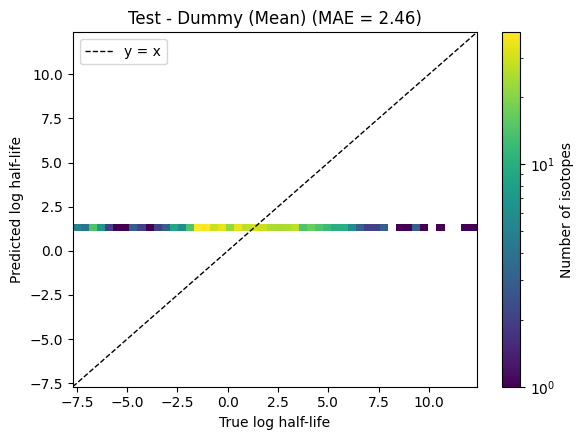

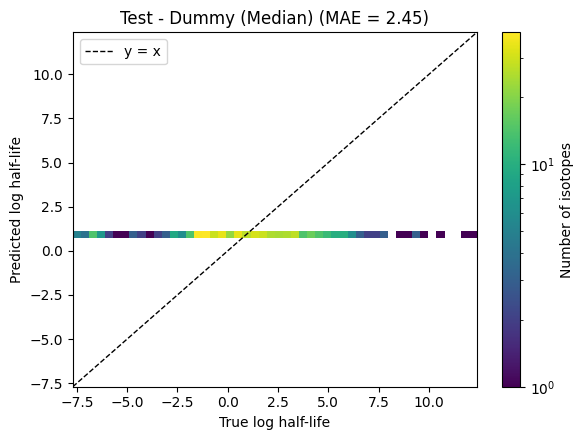

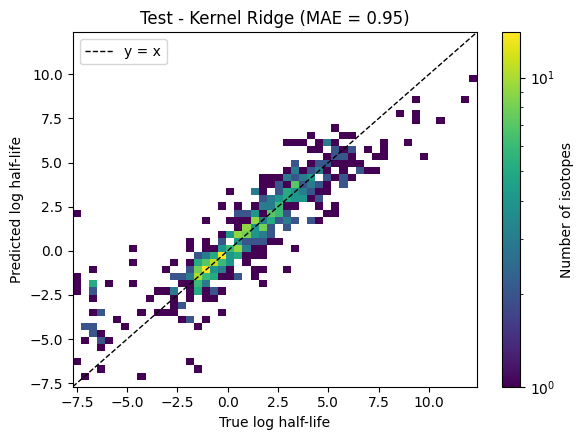

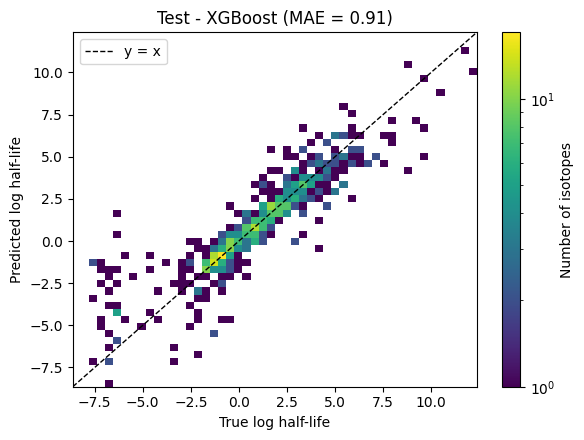

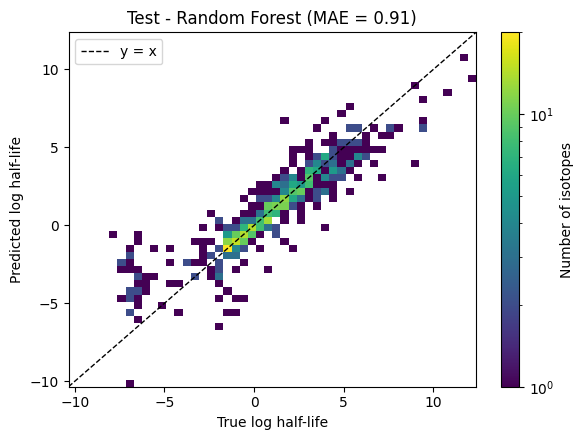

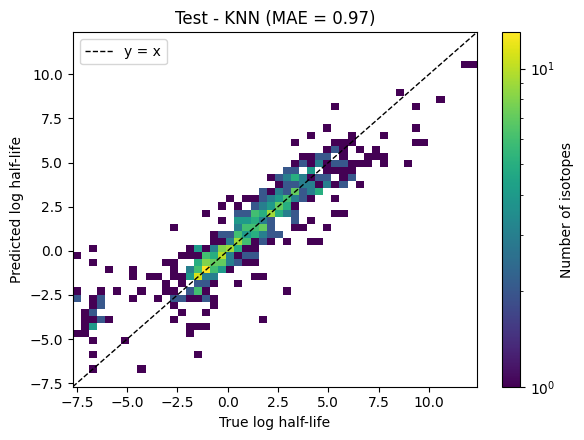

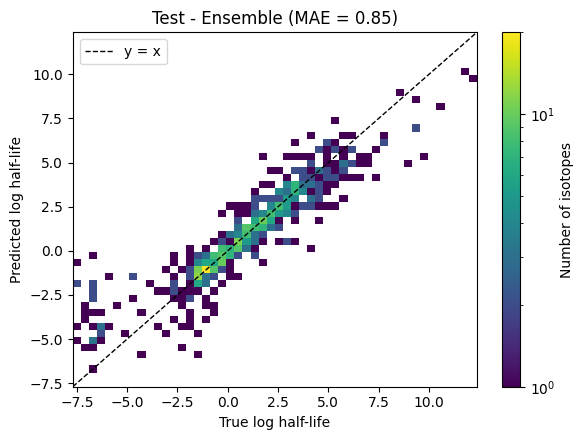

In [17]:

# Define models
models = {
    'Dummy (Mean)': dummyregressor_mean,
    'Dummy (Median)': dummyregressor_median,
    'Kernel Ridge': krr_optimized,
    'XGBoost': xgb_optimized,
    'Random Forest': rf_optimized,
    'KNN': knn_optimized,
    'Ensemble': ensemble_model
}

# Define parity plot function
def hist_density(y_true, y_pred, xlabel='True log half-life',
                 ylabel='Predicted log half-life', title=None, bins=50):

    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)

    lims = [
        min(y_true.min(), y_pred.min()),
        max(y_true.max(), y_pred.max())
    ]

    mae = np.mean(np.abs(y_true - y_pred))

    # Create individual figure
    fig, ax = plt.subplots(figsize=(6, 4.5))

    h = ax.hist2d(
        y_true, y_pred,
        bins=bins,
        range=[lims, lims],
        cmin=1,
        cmap='viridis',
        norm=LogNorm()
    )

    # Add colour bar
    fig.colorbar(h[3], ax=ax, label='Number of isotopes')

    # Add parity line
    ax.plot(lims, lims, 'k--', lw=1, label='y = x')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(
        f"{title} (MAE = {mae:.2f})" if title else f"MAE = {mae:.2f}"
    )

    ax.legend(loc='upper left')

    plt.tight_layout()
    plt.show()


# Generate individual parity plots for all models
for name, model in models.items():

    y_pred = model.predict(df_test[features])

    hist_density(
        df_test[TARGET],
        y_pred,
        title=f'Test - {name}'
    )




In [19]:
#results summary for top 4 performing models



# Create dataframe containing all test results
all_results_test_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_test,
    'Dummy (Median)': dummyregressor_median_results_test,
    'OLS - Baseline': linear_model_results_test,
    'Ridge Regression': ridge_model_results_test,
    'LASSO': lasso_model_results_test,
    'Polynomial Degree 3': polynomial_deg3_results_test,
    'Kernel Ridge Regression': krr_optimized_results_test,
    'XGBoost': xgb_optimized_results_test,
    'Random Forest': rf_optimized_results_test,
    'K Nearest Neighbors': knn_optimized_results_test,
    'Ensemble Model': ensemble_model_results_test
})

# Transpose dataframe
all_results_test_df = all_results_test_df.T

# Add model categories
all_results_test_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression',
    'Ensemble'
])

# Add model names
all_results_test_df.insert(1, 'Model', all_results_test_df.index)

# Reset index
all_results_test_df = all_results_test_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_test_df = all_results_test_df.round(4)


# Display test results
print("\nTEST SET MODEL PERFORMANCE")
display(all_results_test_df)



# Create dataframe containing all training results
all_results_train_df = pd.DataFrame({
    'Dummy (Mean)': dummyregressor_mean_results_train,
    'Dummy (Median)': dummyregressor_median_results_train,
    'OLS - Baseline': linear_model_results_train,
    'Ridge Regression': ridge_model_results_train,
    'LASSO': lasso_model_results_train,
    'Polynomial Degree 3': polynomial_deg3_results_train,
    'Kernel Ridge Regression': krr_optimized_results_train,
    'XGBoost': xgb_optimized_results_train,
    'Random Forest': rf_optimized_results_train,
    'K Nearest Neighbors': knn_optimized_results_train,
    'Ensemble Model': ensemble_model_results_train
})

# Transpose dataframe
all_results_train_df = all_results_train_df.T

# Add model categories
all_results_train_df.insert(0, 'Model Category', [
    'Dummy Regression',
    'Dummy Regression',
    'Linear Regression',
    'Linear Regression',
    'Linear Regression',
    'Polynomial Regression',
    'Kernel Regression',
    'Tree-Based Regression',
    'Tree-Based Regression',
    'Distance-Based Regression',
    'Ensemble'
])

# Add model names
all_results_train_df.insert(1, 'Model', all_results_train_df.index)

# Reset index
all_results_train_df = all_results_train_df.reset_index(drop=True)

# Round to 4 decimal places
all_results_train_df = all_results_train_df.round(4)

# Display results
print("\nTRAINING SET MODEL PERFORMANCE")
display(all_results_train_df)



TEST SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4571,10.4488,11.1946,3.2325,-0.0066
1,Dummy Regression,Dummy (Median),2.4515,10.4088,11.2876,3.2263,-0.0027
2,Linear Regression,OLS - Baseline,2.2752,9.3797,10.5062,3.0626,0.0964
3,Linear Regression,Ridge Regression,2.2752,9.3799,10.5069,3.0627,0.0964
4,Linear Regression,LASSO,2.3126,9.6267,10.7227,3.1027,0.0726
5,Polynomial Regression,Polynomial Degree 3,1.5190,5.0474,9.3652,2.2467,0.5138
6,Kernel Regression,Kernel Ridge Regression,0.9542,2.1335,9.8181,1.4606,0.7945
7,Tree-Based Regression,XGBoost,0.9149,2.0899,8.1399,1.4457,0.7987
8,Tree-Based Regression,Random Forest,0.9091,2.0132,6.9156,1.4189,0.8061
9,Distance-Based Regression,K Nearest Neighbors,0.9731,2.1274,7.6013,1.4586,0.7951



TRAINING SET MODEL PERFORMANCE


,Model Category,Model,mae,mse,max_error,rmse,r^2
0,Dummy Regression,Dummy (Mean),2.4027,10.2367,20.5202,3.1995,0.0000
1,Dummy Regression,Dummy (Median),2.4017,10.2453,20.4271,3.2008,-0.0008
2,Linear Regression,OLS - Baseline,2.2496,9.3905,21.6658,3.0644,0.0827
3,Linear Regression,Ridge Regression,2.2496,9.3905,21.6625,3.0644,0.0827
4,Linear Regression,LASSO,2.2813,9.5936,20.9274,3.0974,0.0628
5,Polynomial Regression,Polynomial Degree 3,1.4013,4.3032,9.4722,2.0744,0.5796
6,Kernel Regression,Kernel Ridge Regression,0.6634,1.0829,8.1500,1.0406,0.8942
7,Tree-Based Regression,XGBoost,0.3313,0.2355,3.1463,0.4853,0.9770
8,Tree-Based Regression,Random Forest,0.3467,0.3191,6.1109,0.5649,0.9688
9,Distance-Based Regression,K Nearest Neighbors,0.0000,0.0000,0.0000,0.0000,1.0000
